# Motor de consultas analíticas en Colab

Entorno de GPU: compila el backend CUDA, genera TPC-H SF10, mide serial / omp / cuda y grafica.
Antes de empezar, en el menú *Entorno de ejecución*, opción *Cambiar tipo de entorno*, elegir una GPU (T4, L4 o A100).

Clonar el repo (o, con `REPO_URL` vacío, subir un `.zip` del proyecto).

In [11]:
# Ruta absoluta: al reejecutar la celda, el directorio actual ya es /content/proyecto.
%cd /content
REPO_URL = "https://github.com/LipezJ/motor-columnar-cpu-gpu.git"  # vacío: subir un .zip del proyecto
import os
if REPO_URL:
    !rm -rf proyecto && git clone -q {REPO_URL} proyecto
else:
    from google.colab import files
    zip_subido = next(iter(files.upload()))
    !unzip -q -o "{zip_subido}" -d proyecto_zip
    # El zip puede traer la carpeta del proyecto dentro o los archivos sueltos.
    raiz = next(os.path.dirname(r) for r, _, fs in os.walk("proyecto_zip") if "Makefile" in fs and "src" in os.listdir(r))
    !rm -rf proyecto && mv "{raiz}" proyecto
%cd /content/proyecto

/content
/content/proyecto


In [2]:
!pip install -q duckdb numpy matplotlib
!nvidia-smi

Tue Nov 10 18:43:43 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100-SXM4-40GB          Off |   00000000:00:04.0 Off |                    0 |
| N/A   31C    P0             45W /  400W |       0MiB /  40960MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [3]:
import re, subprocess
consulta = lambda campo: subprocess.check_output(["nvidia-smi", f"--query-gpu={campo}", "--format=csv,noheader"], text=True).splitlines()[0].strip()
# compute_cap da la arquitectura directamente: 7.5 es sm_75 (T4), 8.0 es sm_80 (A100) y 8.9 es sm_89 (L4).
CUDA_ARCH = "sm_" + consulta("compute_cap").replace(".", "")
GPU = re.sub(r"^(NVIDIA|Tesla)\s+", "", consulta("name")).replace(" ", "-")
print(GPU, CUDA_ARCH)

A100-SXM4-40GB sm_80


In [4]:
!make clean && make CUDA=1 CUDA_ARCH={CUDA_ARCH}

rm -rf build
mkdir -p build
g++ -O3 -std=c++17 -Wall -Wextra -march=native -DCON_CUDA -fopenmp -c -o build/main.o src/main.cpp
g++ -O3 -std=c++17 -Wall -Wextra -march=native -DCON_CUDA -fopenmp -c -o build/datos.o src/datos.cpp
g++ -O3 -std=c++17 -Wall -Wextra -march=native -DCON_CUDA -fopenmp -c -o build/consultas.o src/consultas.cpp
g++ -O3 -std=c++17 -Wall -Wextra -march=native -DCON_CUDA -fopenmp -c -o build/serial.o src/serial.cpp
g++ -O3 -std=c++17 -Wall -Wextra -march=native -DCON_CUDA -fopenmp -c -o build/omp.o src/omp.cpp
nvcc -O3 -std=c++17 -arch=sm_80 -DCON_CUDA -c -o build/cuda.o src/cuda.cu
nvcc -arch=sm_80 -Xcompiler "-fopenmp" -o build/motor build/main.o build/datos.o build/consultas.o build/serial.o build/omp.o build/cuda.o


In [5]:
# Validación rápida en SF1 antes de medir.
!test -d data/sf1 || python scripts/gen_datos.py 1
for q in ["q1", "q3", "q6"]:
    print(q, end=": ")
    !./build/motor data/sf1 cuda {q} --reps 3 | python scripts/validar.py data/sf1/esperado/{q}.csv
print("q1 ingenuo", end=": ")
!MOTOR_Q1_INGENUO=1 ./build/motor data/sf1 cuda q1 --reps 3 | python scripts/validar.py data/sf1/esperado/q1.csv

Generando TPC-H SF=1
  lineitem: 6,001,215 filas
  orders: 1,500,000 filas
  customer: 150,000 filas
Listo: data/sf1
q1: rep,hilos,total_ms,transferencia_ms,computo_ms
0,1,441.713,31.211,1.305
1,1,33.811,32.233,0.961
2,1,33.876,32.326,0.964
OK
q3: rep,hilos,total_ms,transferencia_ms,computo_ms
0,1,301.470,28.192,0.457
1,1,32.913,31.695,0.190
2,1,32.753,31.566,0.190
OK
q6: rep,hilos,total_ms,transferencia_ms,computo_ms
0,1,296.753,21.781,0.322
1,1,23.600,23.094,0.089
2,1,23.664,23.181,0.090
OK
q1 ingenuo: rep,hilos,total_ms,transferencia_ms,computo_ms
0,1,325.437,30.415,32.035
1,1,64.300,31.782,31.805
2,1,64.636,32.168,31.809
OK


In [6]:
# Si data/sf10 viene de una generación interrumpida con una versión anterior del script, se regenera.
!test -f data/sf10/esperado/q6.csv || (rm -rf data/sf10 && python scripts/gen_datos.py 10)

Generando TPC-H SF=10
  lineitem: 59,986,052 filas
  orders: 15,000,000 filas
  customer: 1,500,000 filas
Listo: data/sf10


In [7]:
!python scripts/bench.py --datos data/sf10 --backends serial,omp,cuda,cuda-ingenuo --etiqueta {GPU} --maquina {GPU}

backend      consulta hilos   mediana_ms  válido
serial       q1           1     2107.725  sí
serial       q3           1     5677.899  sí
serial       q6           1      590.648  sí
omp          q1           1      328.274  sí
omp          q1           2      165.520  sí
omp          q1           4       84.492  sí
omp          q1           8       64.332  sí
omp          q1          12       59.092  sí
omp          q3           1     1224.668  sí
omp          q3           2      604.771  sí
omp          q3           4      296.268  sí
omp          q3           8      165.358  sí
omp          q3          12      125.988  sí
omp          q6           1       85.292  sí
omp          q6           2       43.722  sí
omp          q6           4       23.090  sí
omp          q6           8       17.664  sí
omp          q6          12       17.939  sí
cuda         q1           1      318.885  sí
cuda         q3           1      302.852  sí
cuda         q6           1      224.454  sí
cuda-i

usage: graficas.py [-h] [--resultados RESULTADOS] [--salida SALIDA]
graficas.py: error: unrecognized arguments: resultados/A100.csv resultados/duckdb-mac-sf10.csv resultados/mac-sf10.csv resultados/smexa-interleave-sf50.csv resultados/smexa-sf50.csv resultados/T4.csv resultados/TitanX-sf10.csv
resultados/graficas/central.png


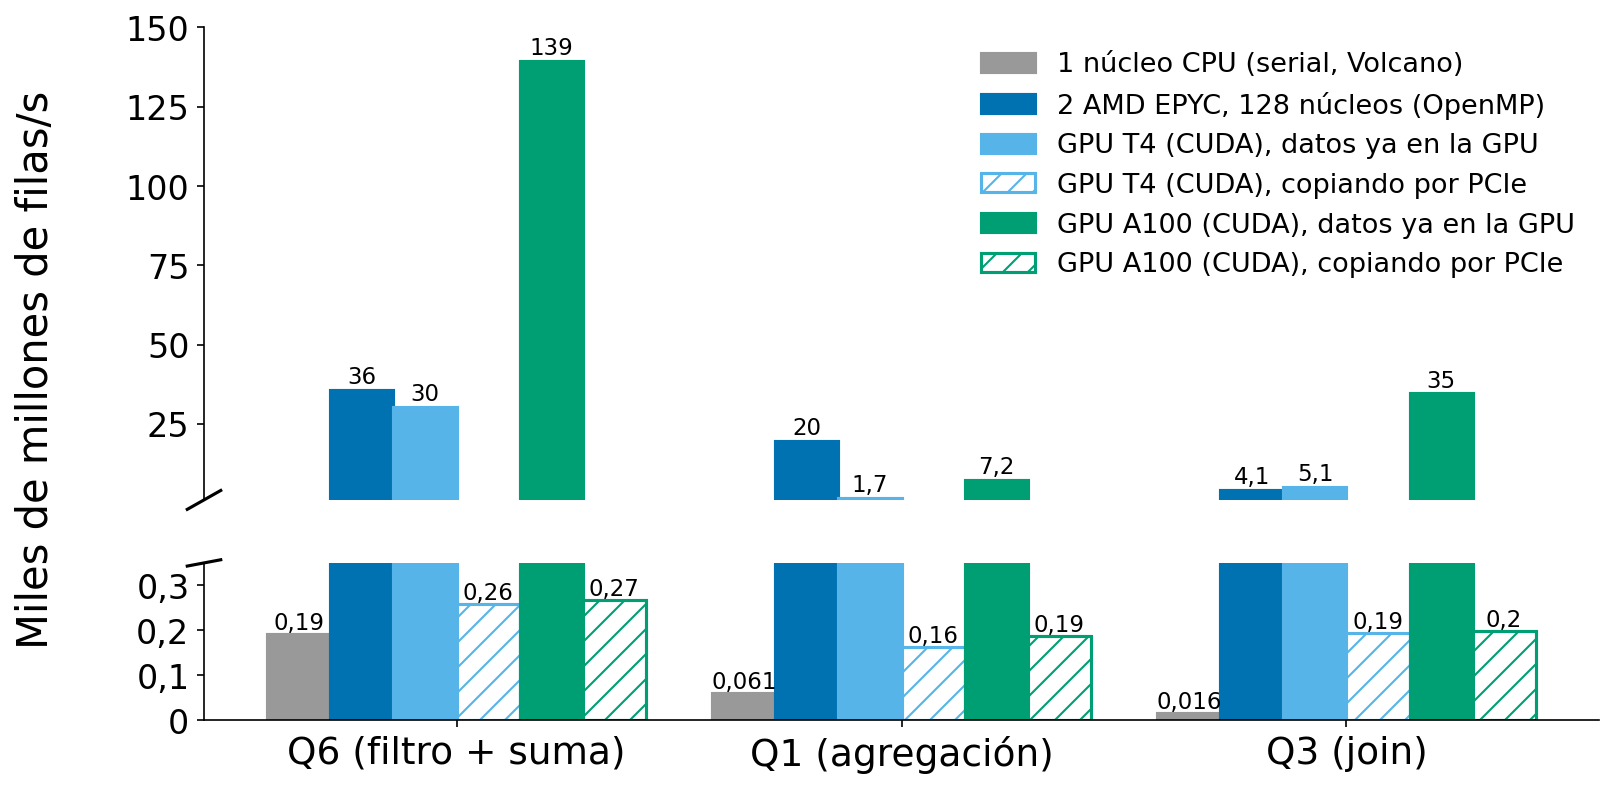

resultados/graficas/contencion.png


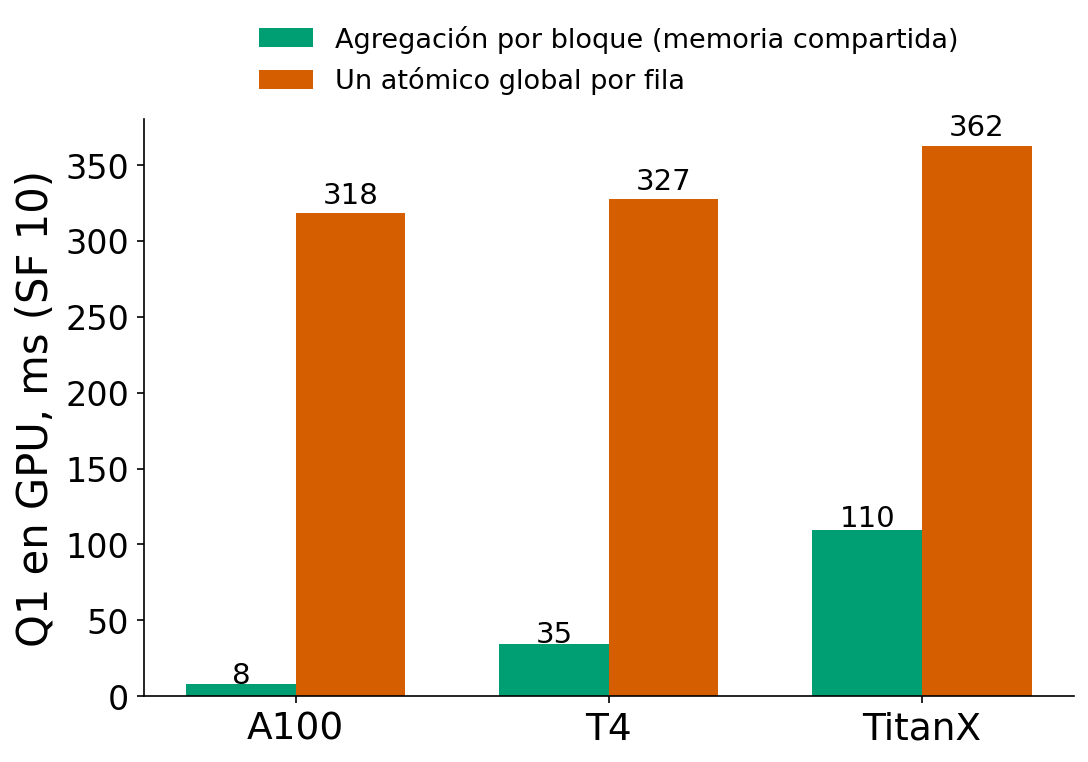

resultados/graficas/desglose.png


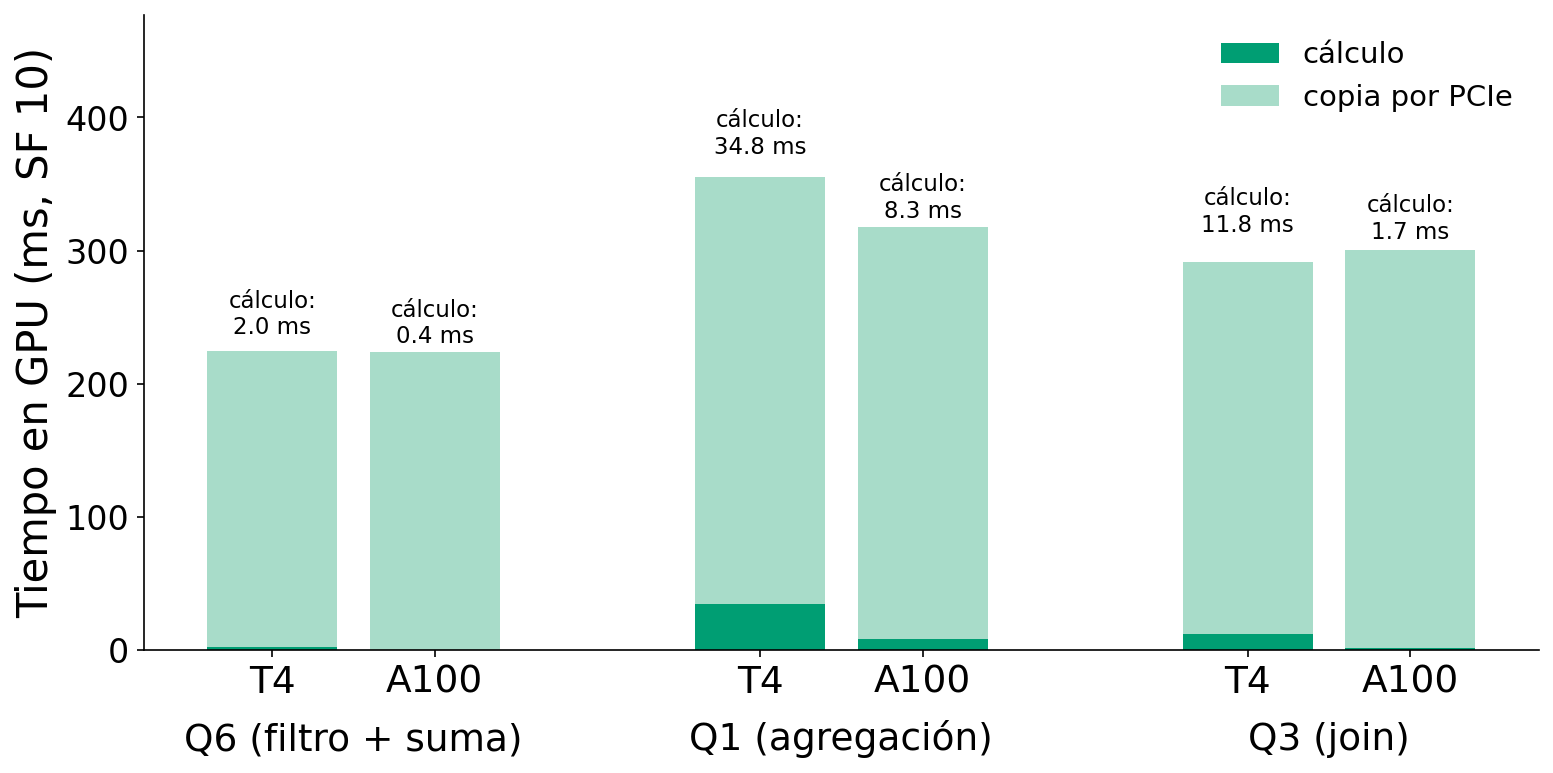

resultados/graficas/escalado.png


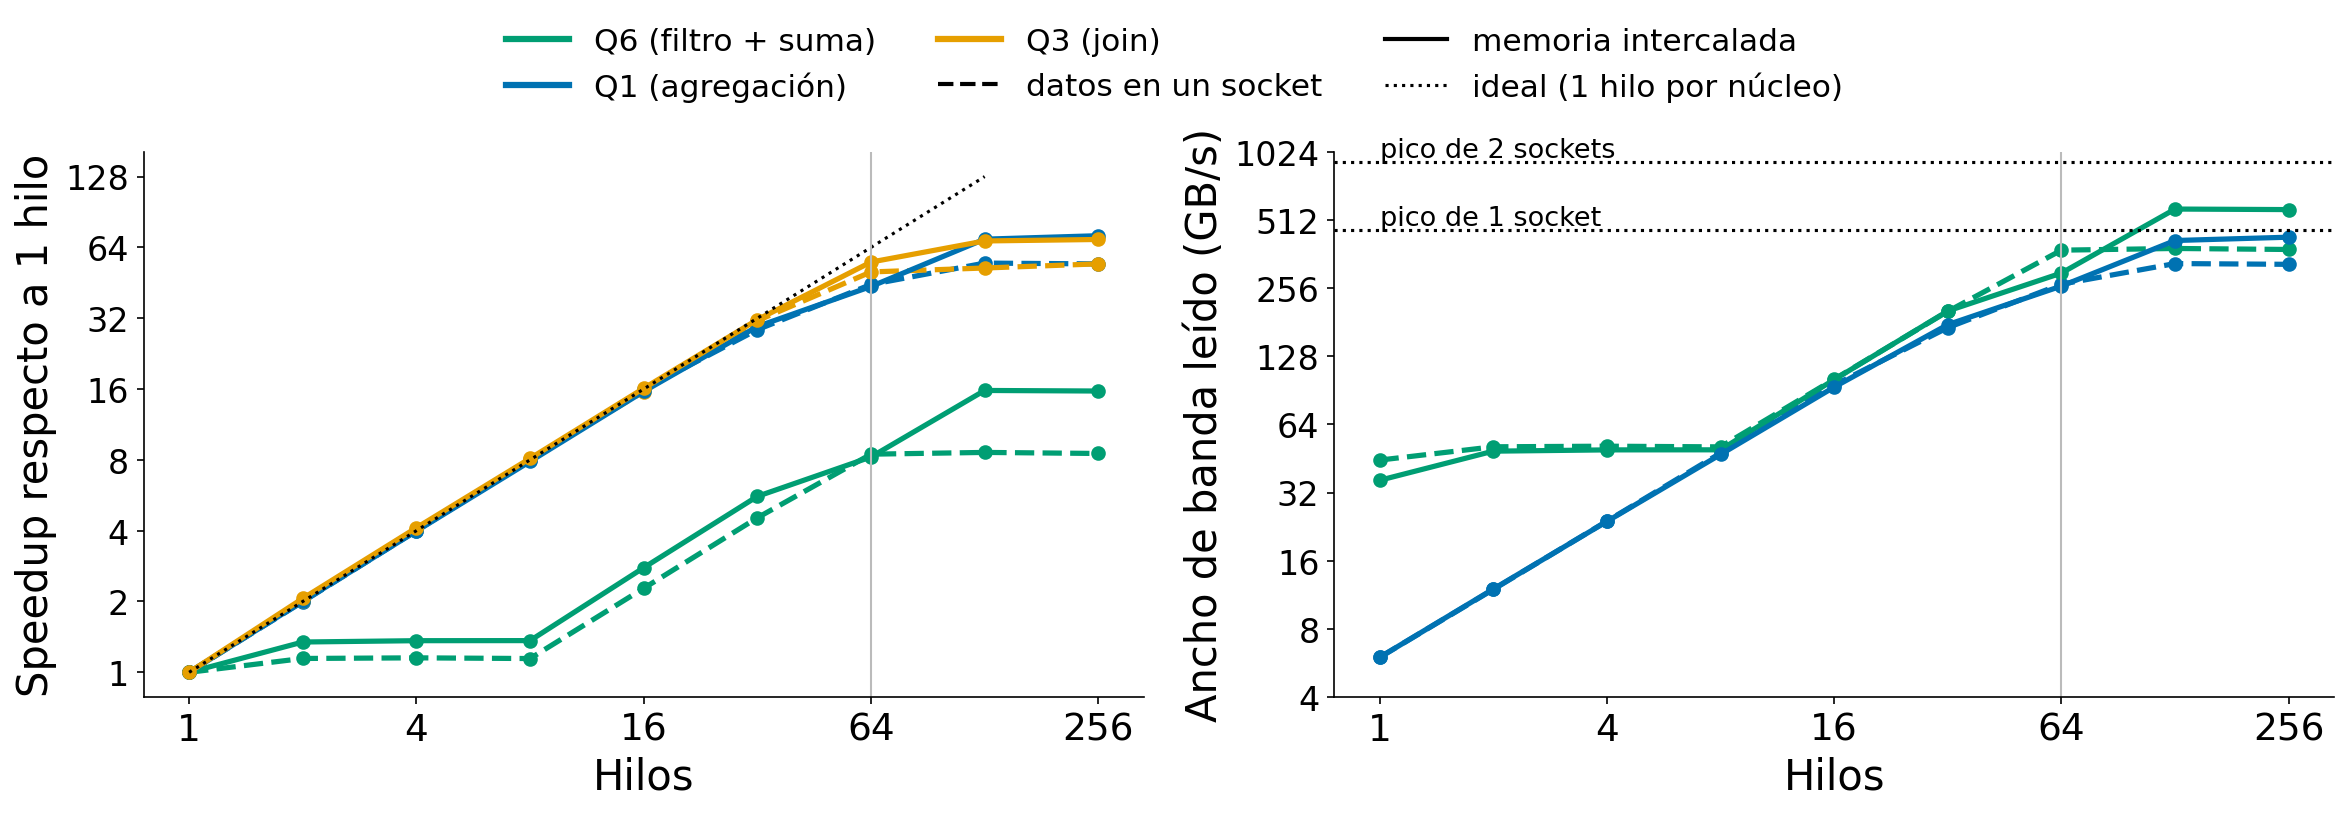

resultados/graficas/gpus.png


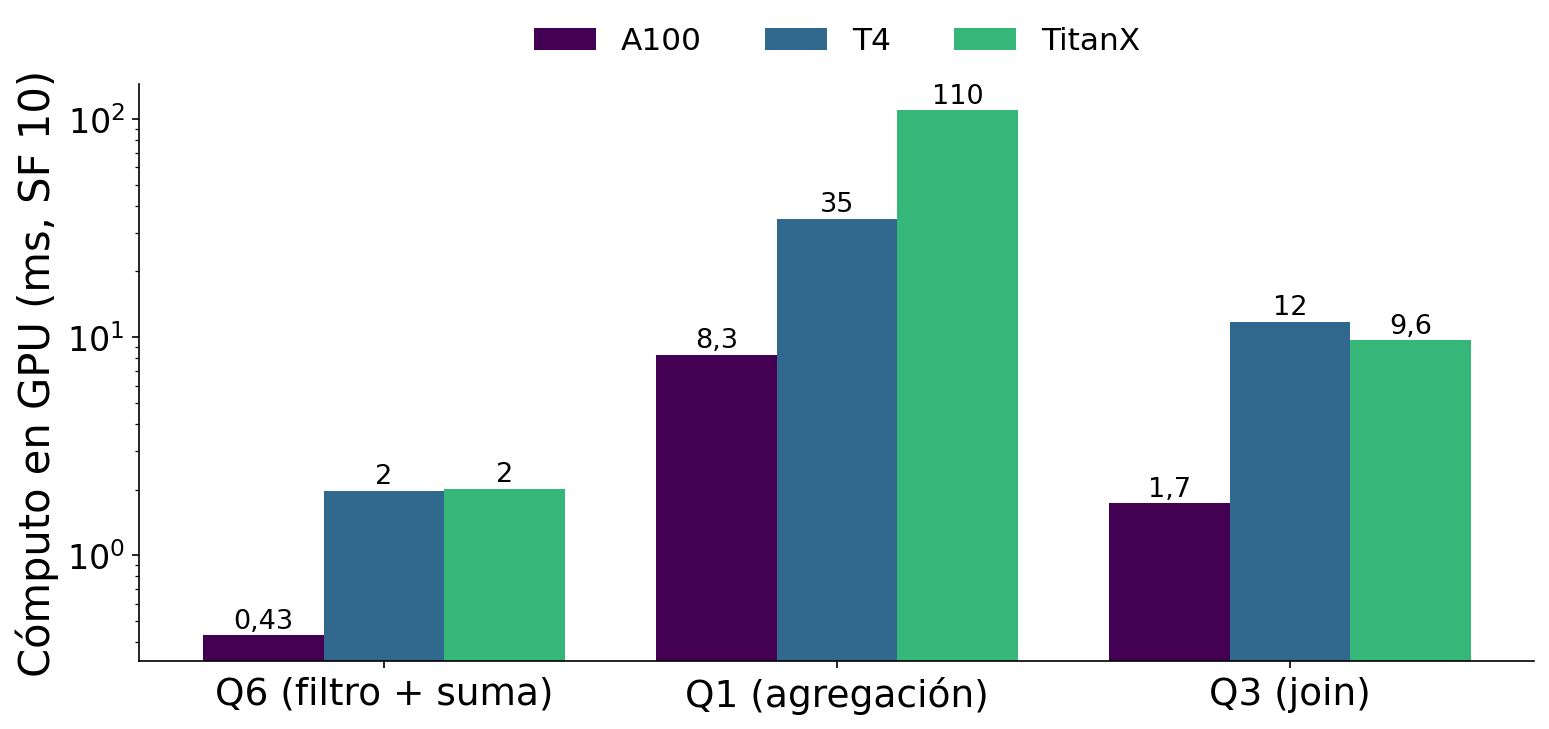

resultados/graficas/relativa.png


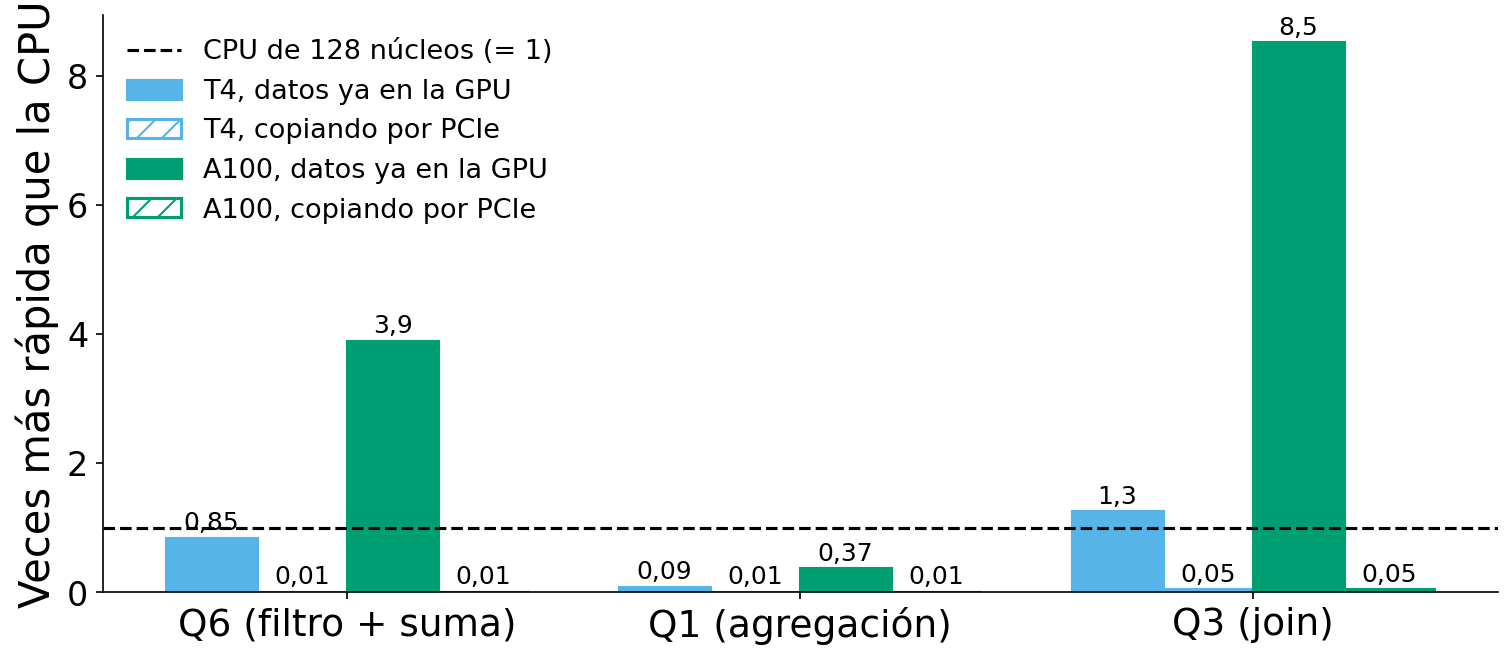

In [12]:
!python scripts/graficas.py resultados/*.csv
from glob import glob
from IPython.display import Image, display
for png in sorted(glob("resultados/graficas/*.png")):
    print(png)
    display(Image(png))

Descargar el CSV para versionarlo en `resultados/` del repo (junto a los de otras GPUs, `graficas.py` genera la comparación por GPU).

In [9]:
from google.colab import files
files.download(f"resultados/{GPU}.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>